# Notebook 05: Model Analysis & Insights

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

model = joblib.load("../models/final_model.joblib")
df = pd.read_csv("../data/processed/model_data.csv")
X = df.drop("Reach", axis=1)
y = df["Reach"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_pred = model.predict(X_test)

## Actual vs Predicted Distribution

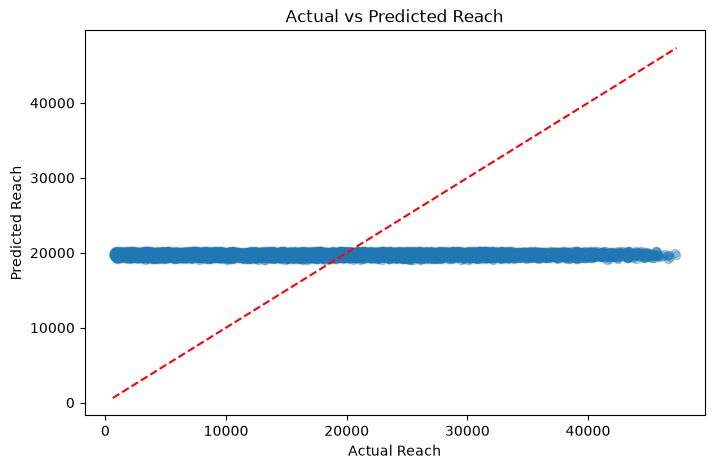

In [2]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "--r")
plt.xlabel("Actual Reach")
plt.ylabel("Predicted Reach")
plt.title("Actual vs Predicted Reach")
plt.savefig("../reports/figures/actual_vs_predicted.png")
plt.show()

## Feature Importance
Extracting feature importance from Random Forest or Gradient Boosting.

In [3]:
regressor = model.named_steps["regressor"]
if hasattr(regressor, "feature_importances_"):
    importances = regressor.feature_importances_
    preprocessor = model.named_steps["preprocessor"]
    cat_cols = preprocessor.transformers_[1][1].get_feature_names_out()
    num_cols = preprocessor.transformers_[0][2]
    feature_names = list(num_cols) + list(cat_cols)
    
    feat_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values(by="Importance", ascending=False)
    
    plt.figure(figsize=(10,6))
    sns.barplot(x="Importance", y="Feature", data=feat_df.head(10))
    plt.title("Top 10 Feature Importances")
    plt.savefig("../reports/figures/feature_importance.png")
    plt.show()